# Air Quality Index Prediction
This project aims to develop a predictive model for estimating air quality index (AQI) based on various environmental factors.

## Importing Required Libraries
We start by importing essential libraries for data manipulation, visualization, and model training.

In [45]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [46]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(
    style="whitegrid",
    context="talk",
    palette="Set2"
)

plt.rcParams["figure.figsize"] = (11, 6)
plt.rcParams["axes.titlesize"] = 16
plt.rcParams["axes.labelsize"] = 13
plt.rcParams["xtick.labelsize"] = 11
plt.rcParams["ytick.labelsize"] = 11


## Loading and Exploring the Dataset
We load the dataset and perform initial exploration to understand its structure and characteristics.

In [47]:
file_path = "city_day.csv"  # Dataset source
df = pd.read_csv(file_path)

# Create a copy for Exploratory Data Analysis
df_eda = df.copy()


In [48]:
#Display Dataset
df

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29526,Visakhapatnam,2020-06-27,15.02,50.94,7.68,25.06,19.54,12.47,0.47,8.55,23.30,2.24,12.07,0.73,41.0,Good
29527,Visakhapatnam,2020-06-28,24.38,74.09,3.42,26.06,16.53,11.99,0.52,12.72,30.14,0.74,2.21,0.38,70.0,Satisfactory
29528,Visakhapatnam,2020-06-29,22.91,65.73,3.45,29.53,18.33,10.71,0.48,8.42,30.96,0.01,0.01,0.00,68.0,Satisfactory
29529,Visakhapatnam,2020-06-30,16.64,49.97,4.05,29.26,18.80,10.03,0.52,9.84,28.30,0.00,0.00,0.00,54.0,Satisfactory


In [49]:
# Display basic info about the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City        29531 non-null  object 
 1   Date        29531 non-null  object 
 2   PM2.5       24933 non-null  float64
 3   PM10        18391 non-null  float64
 4   NO          25949 non-null  float64
 5   NO2         25946 non-null  float64
 6   NOx         25346 non-null  float64
 7   NH3         19203 non-null  float64
 8   CO          27472 non-null  float64
 9   SO2         25677 non-null  float64
 10  O3          25509 non-null  float64
 11  Benzene     23908 non-null  float64
 12  Toluene     21490 non-null  float64
 13  Xylene      11422 non-null  float64
 14  AQI         24850 non-null  float64
 15  AQI_Bucket  24850 non-null  object 
dtypes: float64(13), object(3)
memory usage: 3.6+ MB


## Data Preprocessing
This step involves handling missing values, encoding categorical features, and normalizing numerical features.

In [50]:
# Check the total null values
df.isnull().sum()

City              0
Date              0
PM2.5          4598
PM10          11140
NO             3582
NO2            3585
NOx            4185
NH3           10328
CO             2059
SO2            3854
O3             4022
Benzene        5623
Toluene        8041
Xylene        18109
AQI            4681
AQI_Bucket     4681
dtype: int64

In [51]:
# -------------------------------
# Handle missing values using MEDIAN (EDA)
# -------------------------------

numeric_cols = df_eda.select_dtypes(include=["number"]).columns

df_eda[numeric_cols] = df_eda[numeric_cols].fillna(
    df_eda[numeric_cols].median()
)

# Verify no missing values remain
df_eda[numeric_cols].isnull().sum()

PM2.5      0
PM10       0
NO         0
NO2        0
NOx        0
NH3        0
CO         0
SO2        0
O3         0
Benzene    0
Toluene    0
Xylene     0
AQI        0
dtype: int64

In [52]:
# Handling missing values
# Drop rows where AQI is missing, as it's our target variable
df = df.dropna(subset=['AQI'])

## Exploratory Data Analysis (EDA)
We visualize the data to identify patterns, correlations, and important features.

In [53]:
df.fillna(df.select_dtypes(include=(['number'])).mean(),inplace=True)

/var/folders/8s/cz958b_14qb32rbx6r3l2pqh0000gn/T/ipykernel_14041/1157548274.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.fillna(df.select_dtypes(include=(['number'])).mean(),inplace=True)


In [58]:
# Drop non-numeric and irrelevant columns
drop_columns = ['City', 'Date', 'AQI_Bucket']  # 'City' and 'Date' are categorical, 'AQI_Bucket' is redundant
df = df.drop(columns=drop_columns)

In [59]:
# Define target (dependent variable) and features (independent variables)
target = 'AQI'
features = [col for col in df.columns if col != target]  # All columns except AQI

X = df[features]  # Features dataset
y = df[target]  # Target variable

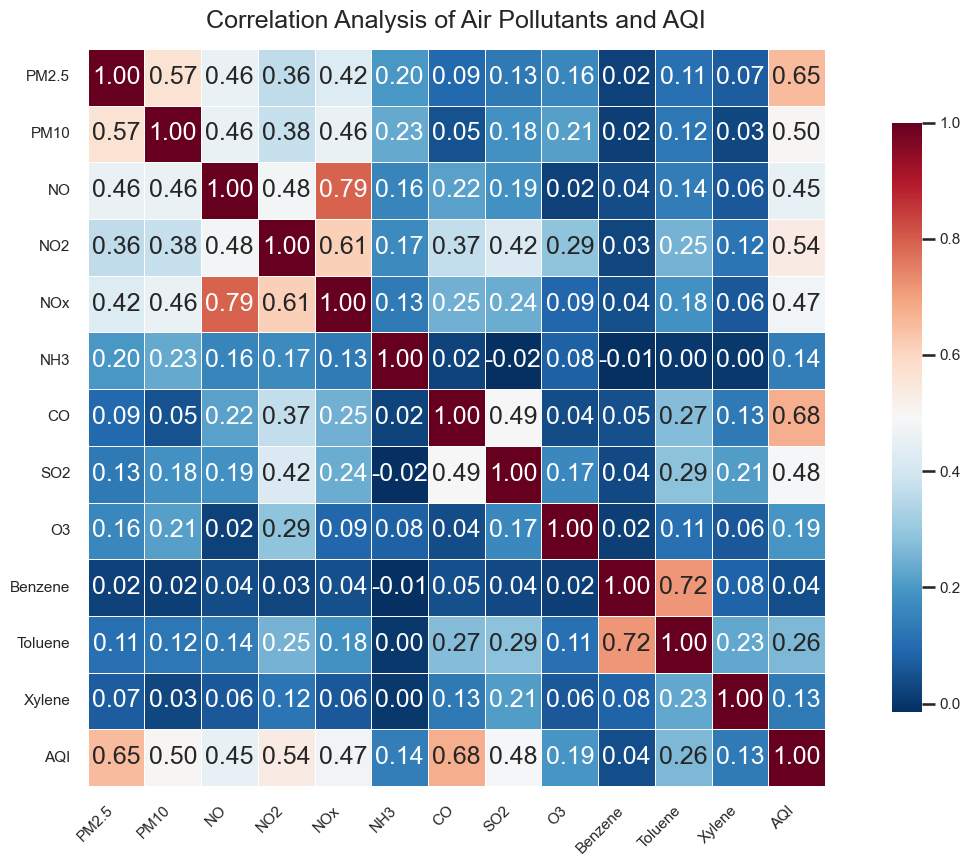

In [60]:
# Select only numerical columns
num_df = df.select_dtypes(include=['number'])

# Compute correlation matrix
corr_matrix = num_df.corr()

# Plot a professional correlation heatmap
plt.figure(figsize=(14, 9))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",          # balanced red-blue for correlations
    linewidths=0.5,
    square=True,            # keeps cells square
    cbar_kws={"shrink": 0.8}
)

plt.title("Correlation Analysis of Air Pollutants and AQI", fontsize=18, pad=15)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


## Splitting Data into Training and Testing Sets
We divide the dataset into training and test sets to evaluate model performance.

In [65]:
# Train-Test Split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## Feature Scaling

In [66]:
# Feature Scaling
# Standardize the dataset to have zero mean and unit variance
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Choosing, Training and Evaluating the Models
We train multiple machine learning models and compare their performance.

In [67]:
# Initialize and define models to be tested
models = {
    "Linear Regression": LinearRegression(),  # Simple baseline model
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),  # Handles non-linearity well
    "XGBoost": XGBRegressor(objective='reg:squarederror', n_estimators=100, random_state=42)  # Gradient boosting for performance
}

In [68]:
# Train and Evaluate Models
results = {}
for name, model in models.items():
    model.fit(X_train_scaled, y_train)  # Train the model on scaled data
    y_pred = model.predict(X_test_scaled)  # Predict on test set
    # Evaluate model performance
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    results[name] = {'MAE': mae, 'RMSE': rmse, 'R2 Score': r2}  # Store results
    print(f"{name} Performance:\nMAE: {mae:.2f}, RMSE: {rmse:.2f}, R2 Score: {r2:.2f}\n")

Linear Regression Performance:
MAE: 31.20, RMSE: 59.11, R2 Score: 0.81

Random Forest Performance:
MAE: 20.59, RMSE: 40.48, R2 Score: 0.91

XGBoost Performance:
MAE: 21.84, RMSE: 42.38, R2 Score: 0.90



In [69]:
# Extract feature importance from trained XGBoost model
xgb_model = models["XGBoost"]

feature_importance = xgb_model.feature_importances_

# Sanity checks
print("Number of features:", len(feature_importance))
print("Number of columns in X:", X.shape[1])


Number of features: 12
Number of columns in X: 12


In [70]:
# Convert results to DataFrame for better visualization
results_df = pd.DataFrame(results).T
print(results_df)

                         MAE       RMSE  R2 Score
Linear Regression  31.203327  59.108362  0.809197
Random Forest      20.591788  40.480720  0.910508
XGBoost            21.835663  42.384466  0.901893


## Model Performance Comparison

<Figure size 1000x600 with 0 Axes>

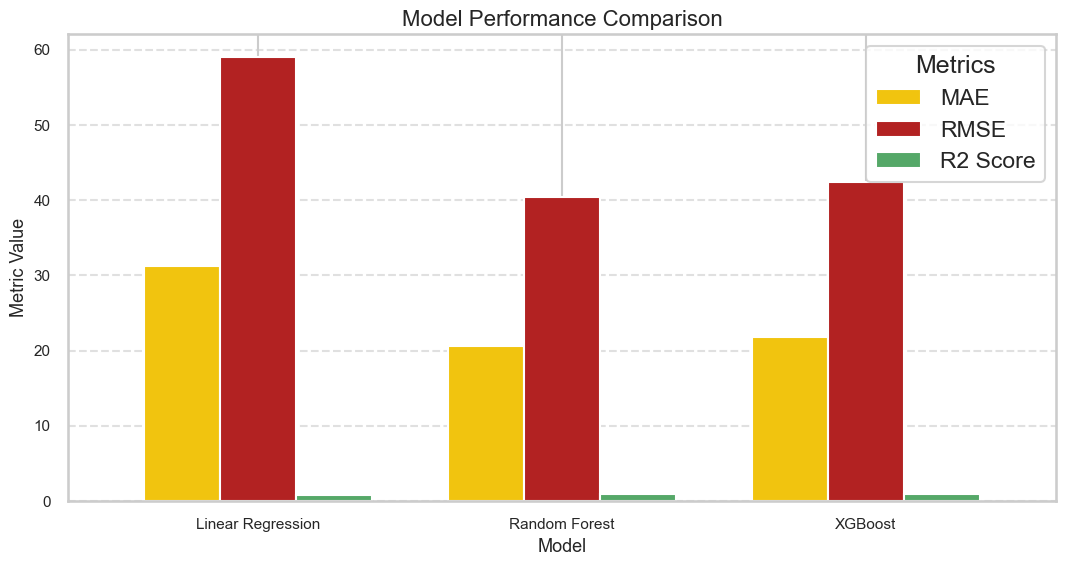

In [71]:
plt.figure(figsize=(10, 6))

results_df.plot(
    kind="bar",
    width=0.75,
    color=["#F1C40F", "#B22222", "#55A868"]
)

plt.title("Model Performance Comparison", fontsize=16)
plt.ylabel("Metric Value")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.legend(title="Metrics")
plt.tight_layout()
plt.show()


## Feature Importance Analysis

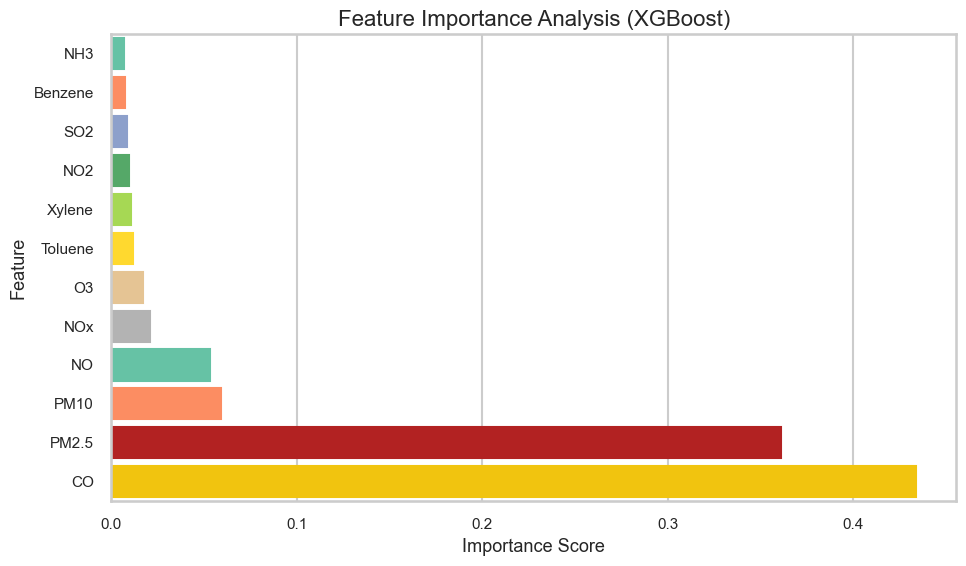

In [72]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Create dataframe
importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": feature_importance
}).sort_values(by="Importance", ascending=True)

# Plot WITHOUT palette or hue
plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

# Base color cycle (all bars different)
base_colors = sns.color_palette("Set2", n_colors=len(importance_df))

# Apply colors manually
for bar, feature, color in zip(ax.patches, importance_df["Feature"], base_colors):
    if feature == "PM2.5":
        bar.set_color("#B22222")   # Firebrick
    elif feature == "CO":
        bar.set_color("#F1C40F")   # Golden Yellow
    elif feature == "NO2":
        bar.set_color("#55A868")   # Green
    else:
        bar.set_color(color)       # Other unique colors

plt.title("Feature Importance Analysis (XGBoost)", fontsize=16)
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


## Hyperparameter Tuning

In [73]:
# Hyperparameter Tuning for XGBoost
# Define parameter grid for tuning
tuning_params = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [3, 5, 7]
}

In [74]:
# Perform grid search with cross-validation
grid_search = GridSearchCV(XGBRegressor(objective='reg:squarederror'), tuning_params, cv=5, scoring='r2')
grid_search.fit(X_train_scaled, y_train)
print(f"Best XGBoost Parameters: {grid_search.best_params_}")  # Output the best parameters

Best XGBoost Parameters: {'learning_rate': 0.2, 'max_depth': 5, 'n_estimators': 100}


## Saving the best model

In [75]:
# Save the best model
import joblib
joblib.dump(models["XGBoost"], "best_aqi_model.pkl")

['best_aqi_model.pkl']

## Optimized Model Training and Evaluation

In [76]:
# Train the best XGBoost model with optimized parameters
best_xgb = XGBRegressor(objective='reg:squarederror',
                        learning_rate=0.2,
                        max_depth=5,
                        n_estimators=100,
                        random_state=42)

best_xgb.fit(X_train_scaled, y_train)
y_pred_xgb = best_xgb.predict(X_test_scaled)

# Evaluate the optimized model
mae = mean_absolute_error(y_test, y_pred_xgb)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
r2 = r2_score(y_test, y_pred_xgb)

print(f"Optimized XGBoost Performance:\nMAE: {mae:.2f}, RMSE: {rmse:.2f}, R2 Score: {r2:.2f}")

# Save the optimized model
import joblib
joblib.dump(best_xgb, "optimized_xgb_model.pkl")

Optimized XGBoost Performance:
MAE: 21.45, RMSE: 42.62, R2 Score: 0.90


['optimized_xgb_model.pkl']



## Making Predictions with the Trained Model

In [77]:
new_data = X_test_scaled[:5]  # Use the first 5 test samples as an example
predictions = best_xgb.predict(new_data)
print("Predicted AQI values:", predictions)

Predicted AQI values: [103.40796 210.93788 100.8787  125.83341  73.10772]


## Weekday / Weekend comparison Demo

In [87]:
# -------------------------------
# Create Day_Type (Weekday / Weekend)
# -------------------------------

# Ensure Date is datetime (df_eda only)
df_eda["Date"] = pd.to_datetime(df_eda["Date"])

# Create Day_Type column
df_eda["Day_Type"] = df_eda["Date"].dt.dayofweek.apply(
    lambda x: "Weekend" if x >= 5 else "Weekday"
)

# Verify
df_eda["Day_Type"].value_counts()


Day_Type
Weekday    21098
Weekend     8433
Name: count, dtype: int64

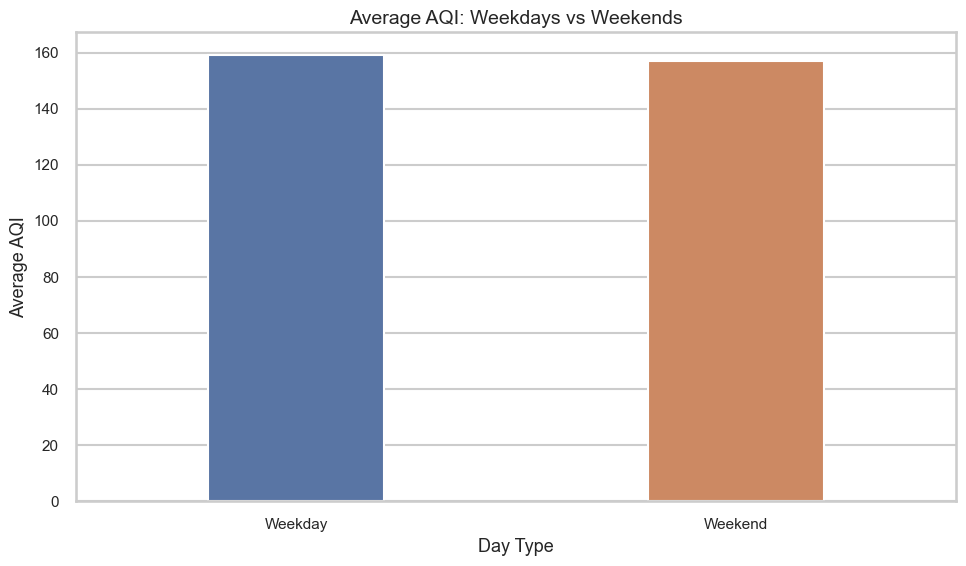

In [88]:
plt.figure(figsize=(10, 6))  # reduced width

sns.barplot(
    data=df_eda,
    x="Day_Type",
    y="AQI",
    hue="Day_Type",
    estimator="mean",
    errorbar=None,
    palette=["#4C72B0", "#DD8452"],
    legend=False,
    width=0.4              # narrower bars
)

plt.title("Average AQI: Weekdays vs Weekends", fontsize=14)
plt.xlabel("Day Type")
plt.ylabel("Average AQI")
plt.tight_layout()
plt.show()

## Festive Vs Non-Festive AQI Prediction 🪔


In [160]:
# -------------------------------
# FESTIVAL ANALYSIS (EDA ONLY)
# -------------------------------

# Ensure Date is datetime (df_eda only)
df_eda["Date"] = pd.to_datetime(df_eda["Date"])

# Approximate Diwali date ranges
diwali_dates = [
    ("2015-11-10", "2015-11-15"),
    ("2016-10-28", "2016-11-02"),
    ("2017-10-17", "2017-10-22"),
    ("2018-11-05", "2018-11-10"),
    ("2019-10-25", "2019-10-30")
]

# Create Festival column
df_eda["Festival"] = "Non-Festival"

for start, end in diwali_dates:
    df_eda.loc[
        (df_eda["Date"] >= start) & (df_eda["Date"] <= end),
        "Festival"
    ] = "Diwali"

# Quick check
df_eda["Festival"].value_counts()

Festival
Non-Festival    29093
Diwali            438
Name: count, dtype: int64

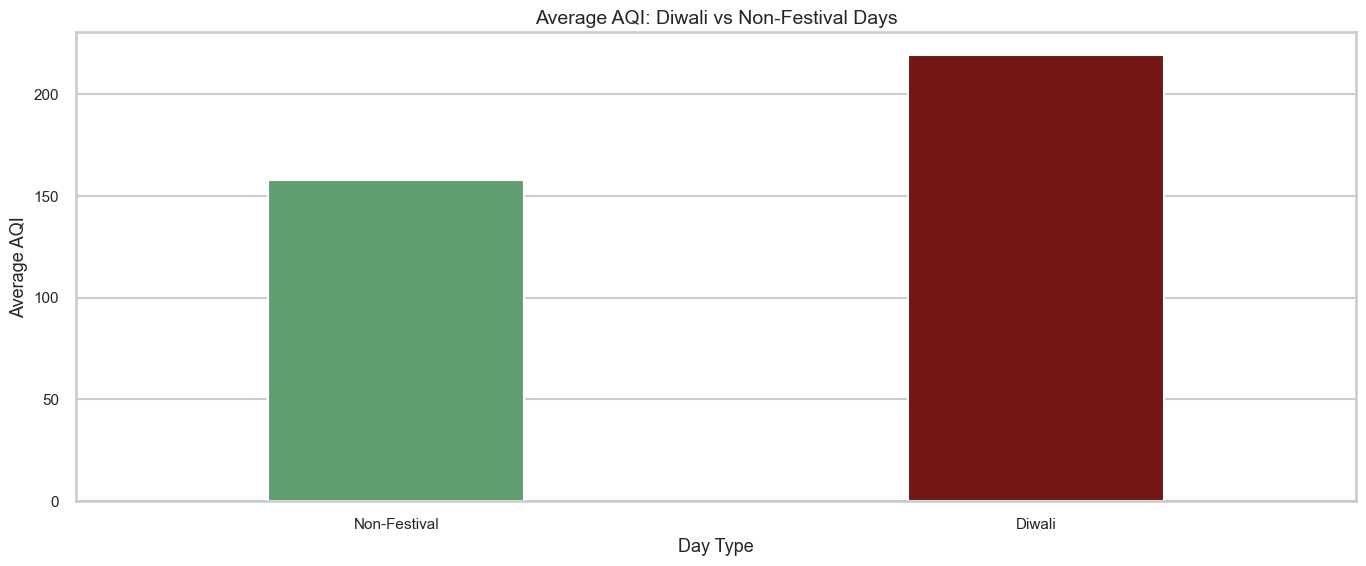

In [161]:
plt.figure(figsize=(14, 6))

sns.barplot(
    data=df_eda,
    x="Festival",
    y="AQI",
    hue="Festival",
    estimator="mean",
    errorbar=None,
    palette=["#55A868", "#820606"],
    legend=False,
    width=0.4
)

plt.title("Average AQI: Diwali vs Non-Festival Days", fontsize=14)
plt.xlabel("Day Type")
plt.ylabel("Average AQI")
plt.tight_layout()
plt.show()

In [162]:
def get_health_risk(aqi):
    if aqi <= 50:
        return "Good"
    elif aqi <= 100:
        return "Satisfactory"
    elif aqi <= 200:
        return "Moderate"
    elif aqi <= 300:
        return "Poor"
    elif aqi <= 400:
        return "Very Poor"
    else:
        return "Severe"


In [163]:
df_eda["Health_Risk"] = df_eda["AQI"].apply(
    lambda x: get_health_risk(x) if pd.notna(x) else None
)


In [164]:
df_eda["Health_Risk"].value_counts()


Health_Risk
Moderate        13510
Satisfactory     8224
Poor             2781
Very Poor        2337
Good             1341
Severe           1338
Name: count, dtype: int64

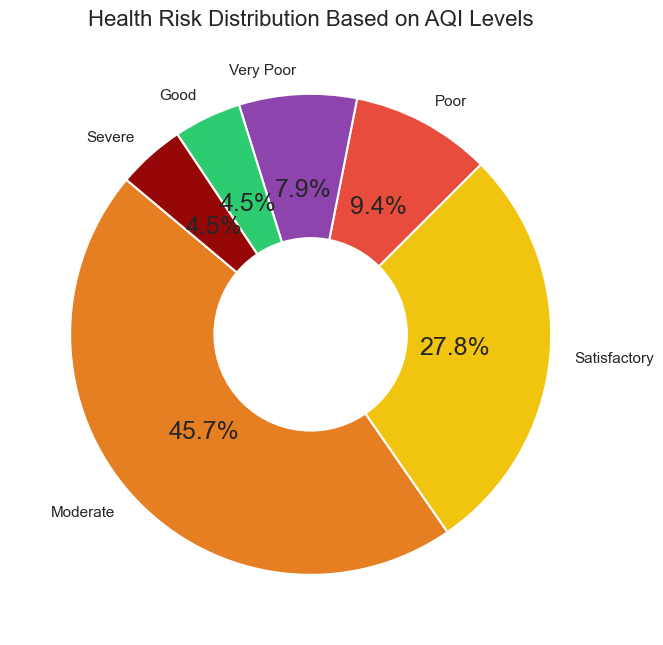

In [165]:
health_counts = df_eda["Health_Risk"].value_counts()

plt.figure(figsize=(7, 7))
plt.pie(
    health_counts,
    labels=health_counts.index,
    autopct="%1.1f%%",
    startangle=140,
    colors=["#E67E22", "#F1C40F", "#E74C3C", "#8E44AD", "#2ECC71", "#960808"]
)

centre_circle = plt.Circle((0, 0), 0.40, fc="white")
plt.gca().add_artist(centre_circle)

plt.title("Health Risk Distribution Based on AQI Levels", fontsize=16)
plt.tight_layout()
plt.show()


## Saving Predictions to a File

In [78]:
pred_df = pd.DataFrame({'Predicted_AQI': predictions})
pred_df.to_csv("aqi_predictions.csv", index=False)
print("Predictions saved to aqi_predictions.csv")

Predictions saved to aqi_predictions.csv


## Dynamic AQI prediction🔮


In [159]:
# -------- USER INPUT --------
city_input = "Kolkata"   
month_input = 2  
year_input = 2026


In [153]:
# Filter data for selected city
city_data = df_eda[df_eda["City"] == city_input]

if city_data.empty:
    raise ValueError("City not found in dataset. Please enter a valid city.")


In [154]:
# Check if prediction is for future
max_year = df_eda["Date"].dt.year.max()
is_future = year_input > max_year


In [155]:
# Filter by selected month
monthly_data = city_data[city_data["Date"].dt.month == month_input]

if monthly_data.empty:
    raise ValueError("No data available for selected month.")

# Estimate AQI (seasonal average)
estimated_aqi = monthly_data["AQI"].mean()


In [156]:
# Estimate pollutant levels for selected month
pollutants = ["PM2.5", "PM10", "NO2", "CO", "O3"]
pollutant_levels = monthly_data[pollutants].mean()

pollutant_levels


PM2.5    105.624386
PM10     194.508947
NO2       77.761404
CO         1.026316
O3        35.430175
dtype: float64

##  Output


In [166]:
risk_level = get_health_risk(estimated_aqi)

print(f"📍 City: {city_input}")
print(f"📅 Month-Year: {month_input}/{year_input}")
print(f"📊 Estimated AQI: {estimated_aqi:.1f}")
print(f"⚠️ Health Risk Level: {risk_level}")

if estimated_aqi > 200:
    print("🚨 Warning: High pollution expected. Avoid outdoor exposure.")
elif estimated_aqi > 100:
    print("⚠️ Caution: Sensitive groups should take precautions.")
else:
    print("✅ AQI expected to be acceptable.")


📍 City: Kolkata
📅 Month-Year: 2/2026
📊 Estimated AQI: 231.3
⚠️ Health Risk Level: Poor
🚨 Warning: High pollution expected. Avoid outdoor exposure.


## 🌍 Environmental & Health Impact

This dynamic AQI prediction system helps users make informed travel and health decisions by estimating future air quality based on historical seasonal patterns. It supports early warning mechanisms and aligns with the goals of Microsoft AI for Earth by promoting public health awareness and sustainable planning.


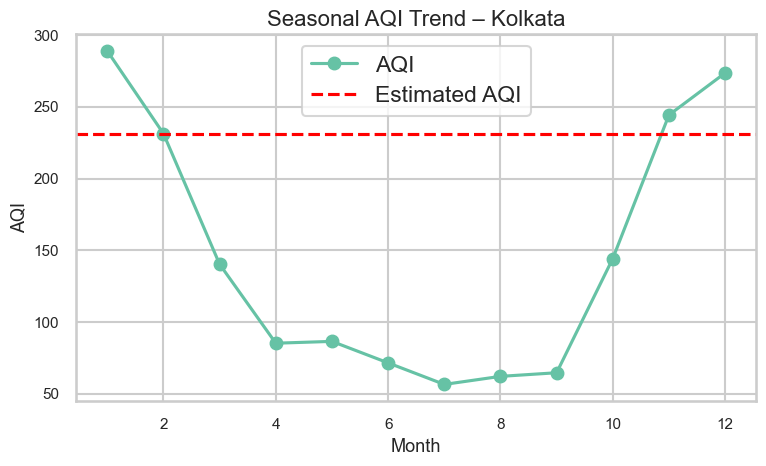

In [158]:
monthly_trend = city_data.groupby(
    city_data["Date"].dt.month
)["AQI"].mean()

plt.figure(figsize=(8, 5))
monthly_trend.plot(marker="o")
plt.axhline(estimated_aqi, color="red", linestyle="--", label="Estimated AQI")

plt.title(f"Seasonal AQI Trend – {city_input}")
plt.xlabel("Month")
plt.ylabel("AQI")
plt.legend()
plt.tight_layout()
plt.show()


## Actual vs. Predicted AQI Visualization

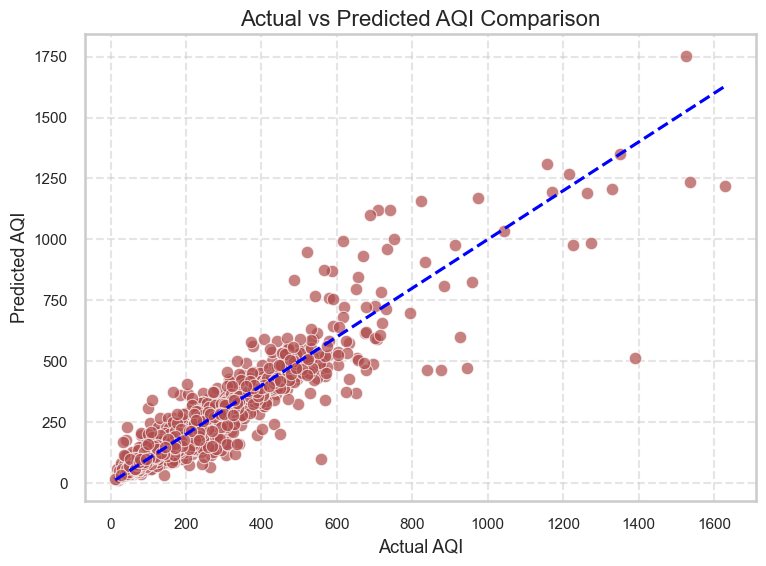

In [168]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_test,
    y=y_pred,
    color="#B04C4C",
    alpha=0.7,
    s=80
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--",
    color="blue"
)

plt.xlabel("Actual AQI")
plt.ylabel("Predicted AQI")
plt.title("Actual vs Predicted AQI Comparison", fontsize=16)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()